# ACROBAT — Demostración y evaluación del agente entrenado

**Objetivo de la entrega:** cargar un modelo tabular Q-Learning o Dyna-Q ya entrenado (`.pkl`), reconstruir su política mediante la discretización guardada, ejecutar episodios en `Acrobot-v1` y registrar los resultados. Este notebook sustituye la política aleatoria del notebook inicial por una política **greedy** sobre la tabla Q.

**Ejecución:** abrir desde la carpeta `acrobot/notebooks/`, con el entorno Python de Poetry del proyecto. Se recomienda ejecutar `poetry run jupyter lab` desde `acrobot/` (si Jupyter está instalado en ese entorno). No se entrena de nuevo ni se modifican los modelos. **Solo cargar archivos `.pkl` propios o de confianza**, porque `pickle` puede ejecutar código durante la carga.

## 1. Dependencias y rutas

Desde `acrobot/`: `poetry install`. Si falta Jupyter: `poetry add --group dev notebook ipykernel`. En la notebook seleccioná el kernel asociado al entorno virtual de Poetry. Se admiten ubicaciones de ejecución desde `acrobot/` o `acrobot/notebooks/`.

In [2]:
%pip install pandas

  Using cached pandas-2.3.3-cp310-cp310-macosx_11_0_arm64.whl.metadata (91 kB)
Using cached pandas-2.3.3-cp310-cp310-macosx_11_0_arm64.whl (10.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install pandas matplotlib

  Using cached matplotlib-3.10.9-cp310-cp310-macosx_11_0_arm64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.65.0-cp310-cp310-macosx_10_9_universal2.whl.metadata (125 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp310-cp310-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.10.9-cp310-cp310-macosx_11_0_arm64.whl (8.2 MB)
Using cached contourpy-1.3.2-cp310-cp310-macosx_11_0_arm64.whl (253 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.65.0-cp310-cp310-macosx_10_9_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp310-cp310-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-12.3.0-cp310-cp310-macosx_11_0_arm64.whl (4.8 MB)
Using cached pyparsing-3.3.3-p

In [5]:
from pathlib import Path
import sys
import json
import pickle
import numpy as np
import gymnasium as gym
import pandas as pd
from IPython.display import display, HTML

cwd = Path.cwd().resolve()
candidates = [cwd, cwd.parent]
ROOT = next((p for p in candidates if (p / "src" / "discretizer.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ejecutá este notebook desde acrobot/ o acrobot/notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.discretizer import Discretizer  # necesario para deserializar el modelo

(ROOT / "results" / "final").mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Python:", sys.version.split()[0], "| Gymnasium:", gym.__version__)

Proyecto: /Users/tatiana/Desktop/IA/Obligatorio_IA_Agosto_2026/obligatorio-ia/acrobot
Python: 3.10.21 | Gymnasium: 1.4.0


## 2. Seleccionar y cargar el modelo final

Por defecto, el archivo de entrega es `models/final/modelo_final.pkl`, una copia del modelo elegido tras los experimentos. Si todavía no lo copiaste, el notebook puede utilizar temporalmente `models/hp_gamma_0999_seed123.pkl`. Para la entrega, **debe existir el archivo final** y estar documentada su procedencia.

Para prepararlo desde `acrobot/`:

```bash
mkdir -p models/final
cp models/hp_gamma_0999_seed123.pkl models/final/modelo_final.pkl
```

Este candidato fue elegido por su rendimiento individual inicial; la validación reservada y la comparación con Dyna-Q deben respaldar la elección definitiva.

In [6]:
FINAL_MODEL = ROOT / "models" / "final" / "modelo_final.pkl"
FALLBACK_MODEL = ROOT / "models" / "hp_gamma_0999_seed123.pkl"
MODEL_PATH = FINAL_MODEL if FINAL_MODEL.exists() else FALLBACK_MODEL
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el modelo final ({FINAL_MODEL}) ni el candidato ({FALLBACK_MODEL}). "
        "Copiá un .pkl entrenado a models/final/modelo_final.pkl."
    )

with MODEL_PATH.open("rb") as f:
    artifact = pickle.load(f)  # Solo modelos .pkl propios/de confianza

required = {"algorithm", "discretizer", "q", "config"}
if not isinstance(artifact, dict) or not required.issubset(artifact):
    raise ValueError("El .pkl no tiene el formato esperado de src.train.")

discretizer = artifact["discretizer"]
q = artifact["q"]
config = artifact["config"]
if not isinstance(q, dict):
    raise TypeError("La tabla Q guardada debe ser un diccionario.")

print("Archivo seleccionado:", MODEL_PATH.relative_to(ROOT))
print("Algoritmo:", artifact["algorithm"])
print("Discretización:", discretizer.mode, "; bins:", discretizer.bins)
print("Estados almacenados:", len(q), "; estados teóricos:", discretizer.n_states_theoretical)
print("Parámetros:", json.dumps(config, indent=2, ensure_ascii=False))
if MODEL_PATH != FINAL_MODEL:
    print("AVISO: se está usando un candidato, no models/final/modelo_final.pkl")

Archivo seleccionado: models/final/modelo_final.pkl
Algoritmo: q
Discretización: angles ; bins: 8
Estados almacenados: 730 ; estados teóricos: 4096
Parámetros: {
  "mode": "angles",
  "bins": 8,
  "episodes": 5000,
  "seed": 123,
  "alpha": 0.1,
  "gamma": 0.999,
  "eps_min": 0.05,
  "eps_decay": 0.999,
  "planning_steps": 0
}


/var/folders/fc/_3w_jdzj2l51rx70rq_trmx00000gn/T/ipykernel_63809/3085501910.py:11: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  artifact = pickle.load(f)  # Solo modelos .pkl propios/de confianza


## 3. Política greedy

Para cada observación continua, se obtiene el estado discretizado y se elige una acción de valor Q máximo. Los empates se resuelven aleatoriamente con un generador independiente, como en `src.evaluate`. Si aparece un estado no visitado, se elige una acción aleatoria sin alterar la tabla.

In [7]:
def greedy_action(obs, rng):
    state = discretizer.transform(obs)
    values = q.get(state)  # .get no inserta estados nuevos
    if values is None:
        return int(rng.integers(3))
    values = np.asarray(values, dtype=float)
    if values.shape != (3,):
        raise ValueError(f"Se esperaban 3 valores Q por estado; recibido {values.shape}")
    return int(rng.choice(np.flatnonzero(values == values.max())))

print("Política cargada. Número de estados:", len(q))

Política cargada. Número de estados: 730


## 4. Evaluación reproducible del modelo

Se evalúa la política sin aprendizaje ni exploración epsilon-greedy. La recompensa del último paso exitoso es 0; si no se logra el objetivo antes de 700 pasos, se registra un fracaso. **Las semillas reservadas se utilizan una sola vez como validación final**, y no para seguir modificando la configuración.

In [8]:
EVAL_EPISODES = 200
EVAL_SEED = 50000
MAX_STEPS = 700

def run_episode(env, seed, rng, collect_frames=False):
    obs, _ = env.reset(seed=int(seed))
    total_return = 0.0
    frames = []
    if collect_frames:
        frames.append(env.render())
    for step in range(1, MAX_STEPS + 1):
        action = greedy_action(obs, rng)
        obs, reward, terminated, truncated, _ = env.step(action)
        total_return += float(reward)
        if collect_frames:
            frames.append(env.render())
        if terminated or truncated:
            break
    return {
        "seed": int(seed),
        "steps": int(step),
        "return": float(total_return),
        "success": bool(terminated),
    }, frames

def evaluate_model(episodes=EVAL_EPISODES, seed=EVAL_SEED):
    rng = np.random.default_rng(seed)
    env = gym.make("Acrobot-v1", render_mode=None, max_episode_steps=MAX_STEPS)
    try:
        records = [run_episode(env, seed + i, rng)[0] for i in range(episodes)]
    finally:
        env.close()
    df = pd.DataFrame(records)
    summary = {
        "model": str(MODEL_PATH.relative_to(ROOT)),
        "algorithm": artifact["algorithm"],
        "episodes": episodes,
        "seed": seed,
        "mean_return": float(df["return"].mean()),
        "std_return": float(df["return"].std(ddof=1)) if episodes > 1 else 0.0,
        "mean_steps": float(df["steps"].mean()),
        "std_steps": float(df["steps"].std(ddof=1)) if episodes > 1 else 0.0,
        "success_rate": float(df["success"].mean()),
    }
    return df, summary

eval_df, eval_summary = evaluate_model()
print(json.dumps(eval_summary, indent=2, ensure_ascii=False))
display(eval_df.head(10))

{
  "model": "models/final/modelo_final.pkl",
  "algorithm": "q",
  "episodes": 200,
  "seed": 50000,
  "mean_return": -133.165,
  "std_return": 36.57274399077919,
  "mean_steps": 134.165,
  "std_steps": 36.57274399077919,
  "success_rate": 1.0
}


,seed,steps,return,success
0,50000,113,-112.0,True
1,50001,143,-142.0,True
2,50002,116,-115.0,True
3,50003,146,-145.0,True
4,50004,123,-122.0,True
5,50005,103,-102.0,True
6,50006,170,-169.0,True
7,50007,166,-165.0,True
8,50008,165,-164.0,True
9,50009,132,-131.0,True


## 5. Guardar CSV, JSON y gráfico de la evaluación

Estos archivos constituyen evidencia reproducible para el informe y el ZIP de entrega. La misma evaluación también puede ejecutarse desde consola con `python -m src.evaluate`.

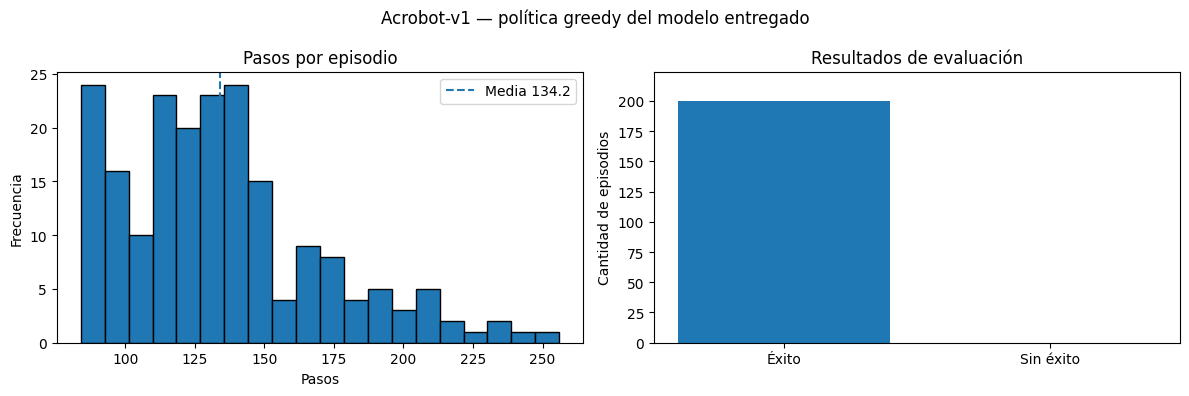

Archivos:
results/final/episodios_modelo_final_notebook.csv
results/final/evaluacion_modelo_final_notebook.json
results/final/evaluacion_modelo_final_notebook.png


In [11]:
import matplotlib.pyplot as plt
out = ROOT / "results" / "final"
json_path = out / "evaluacion_modelo_final_notebook.json"
csv_path = out / "episodios_modelo_final_notebook.csv"
png_path = out / "evaluacion_modelo_final_notebook.png"

eval_df.to_csv(csv_path, index=False)
json_path.write_text(json.dumps(eval_summary, indent=2, ensure_ascii=False), encoding="utf-8")


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eval_df["steps"], bins=20, edgecolor="black")
axes[0].axvline(eval_summary["mean_steps"], linestyle="--", label=f'Media {eval_summary["mean_steps"]:.1f}')
axes[0].set(title="Pasos por episodio", xlabel="Pasos", ylabel="Frecuencia")
axes[0].legend()
counts = eval_df["success"].value_counts().reindex([True, False], fill_value=0)
axes[1].bar(["Éxito", "Sin éxito"], [counts[True], counts[False]])
axes[1].set(title="Resultados de evaluación", ylabel="Cantidad de episodios", ylim=(0, EVAL_EPISODES * 1.12))
fig.suptitle("Acrobot-v1 — política greedy del modelo entregado")
fig.tight_layout()
fig.savefig(png_path, dpi=180)
plt.show()
print("Archivos:", csv_path.relative_to(ROOT), json_path.relative_to(ROOT), png_path.relative_to(ROOT), sep="\n")

## 6. Demostración visual del agente entrenado

La representación usa `rgb_array`, por lo que funciona también en Jupyter sin abrir una ventana gráfica del sistema. El ejemplo recorre un episodio controlado por la política aprendida, **no una política aleatoria**.

Para evitar que el notebook sea demasiado pesado se muestran cuadros espaciados; el número de pasos y el retorno corresponden al episodio completo.

In [12]:
from matplotlib.animation import FuncAnimation

DEMO_SEED = 60000
FRAME_STRIDE = 5
rng_demo = np.random.default_rng(DEMO_SEED)
env_demo = gym.make("Acrobot-v1", render_mode="rgb_array", max_episode_steps=MAX_STEPS)
try:
    demo_result, all_frames = run_episode(env_demo, DEMO_SEED, rng_demo, collect_frames=True)
finally:
    env_demo.close()

frames = all_frames[::FRAME_STRIDE]
if frames[-1] is not all_frames[-1]:
    frames.append(all_frames[-1])

fig, ax = plt.subplots(figsize=(6, 5))
ax.axis("off")
image_obj = ax.imshow(frames[0])

def update_frame(index):
    image_obj.set_data(frames[index])
    return (image_obj,)

ani = FuncAnimation(fig, update_frame, frames=len(frames), interval=75, blit=True)
plt.close(fig)
print("Demostración:", demo_result)
print("Cuadros mostrados:", len(frames), "de", len(all_frames))
display(HTML(ani.to_jshtml()))

Demostración: {'seed': 60000, 'steps': 122, 'return': -121.0, 'success': True}
Cuadros mostrados: 26 de 123


## 7. Verificación de integridad y entrega

Antes de entregar, confirmar que el modelo está en `models/final/modelo_final.pkl`, que el notebook se ejecuta de principio a fin y que sus resultados concuerdan con `src.evaluate`. Se sugiere entregar el notebook sin salidas voluminosas de animación (Jupyter: *Restart & Clear Outputs*) o conservar solo capturas/figuras pequeñas en el informe.

**Archivos mínimos de ACROBAT:** `src/discretizer.py`, `src/rl.py`, `src/train.py`, `src/evaluate.py`, `models/final/modelo_final.pkl`, este notebook y los archivos de evaluación. Incluir `pyproject.toml`, `poetry.lock` y las instrucciones de ejecución.

**Nota metodológica:** el modelo candidato con γ=0.999 y semilla 123 obtuvo 136,81 pasos y 100% de éxito en las 100 evaluaciones utilizadas durante la selección. Ese resultado no debe presentarse como el de la evaluación reservada de 200 episodios, cuyo valor debe obtenerse ejecutando este notebook.